# Picking Ramen's active set with CLIP's zero-shot prediction (ImageNet-C)

For every query, Ramen retrieves the nearest memory entry from **every** non-empty class queue and averages their gradients with equal class weight. On ImageNet that means up to 1000 classes vote on every update, most of them unrelated to the query. This notebook makes each class queue's vote depend on the query's own zero-shot prediction.

The rules are small classes in `src/methods/RamenActive.py`, chosen with the config key `active_set` (`cfg/ImageNetC5K/RamenActive.yaml`):

| `active_set` | class weight w[b, c] | knob |
|---|---|---|
| `all` | 1 for every class (exactly Ramen) | |
| `topm` | 1 for the query's m most likely zero-shot classes, 0 otherwise | `top_m` |
| `prob` | CLIP's zero-shot probability softmax(logits / T) | `temperature` |

**Self-retrieval.** Ramen writes a batch into memory before retrieving, so the queue of the query's own zero-shot class holds the query itself at distance 0. With `topk: 1` that class always contributes the query's own gradient. `topm` with m=1 is therefore per-sample adaptation, and `prob` up-weights the query's own gradient by its zero-shot confidence. The `self weight` column below tracks this.

**Adding a selector.** Subclass `ClassSelector` in `RamenActive.py`, implement `__call__(zs_logits) -> (B, C) weights`, and add it to `SELECTORS`.

The last section uses `CacheViewer` (`new_experiments/cache_viewer.py`) to show the images in the memory at the moments the model gets confused.

In [1]:
%load_ext autoreload
%autoreload 2

import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '1')  # pick a free GPU; must be set before torch is imported

import numpy as np
import pandas as pd
from ramen_analysis import make_experiment
from cache_viewer import CacheViewer

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
exp = make_experiment('ImageNetC5K', tta_mode='mixed', batch_size=100, n_per_domain=None, seed=0,
                      num_workers=16).load()
acc = exp.evaluate()   # NoAdapt + Ramen (cached)
acc

ImageNetC5K: 15 corruptions x 5000 images, 1000 classes, model=clip_vitbase16, mode=mixed
NoAdapt: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_NoAdapt.pkl


Ramen: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_Ramen.pkl


,NoAdapt,Ramen,delta
gaussian_noise,15.00,22.24,7.24
shot_noise,16.88,23.18,6.30
impulse_noise,15.36,23.64,8.28
defocus_blur,25.68,28.52,2.84
glass_blur,16.90,24.20,7.30
motion_blur,26.82,32.88,6.06
zoom_blur,24.58,29.76,5.18
snow,34.00,37.40,3.40
frost,33.02,34.98,1.96
fog,39.18,44.14,4.96


## 1. Run every variant
First check: `active_set: all` must give exactly Ramen's predictions. Each run takes about 8 minutes.

In [3]:
VARIANTS = {
    'active_all':   {'active_set': 'all'},
    'active_top2':  {'active_set': 'topm', 'top_m': 2},
    'active_top5':  {'active_set': 'topm', 'top_m': 5},
    'active_top20': {'active_set': 'topm', 'top_m': 20},
    'active_top100': {'active_set': 'topm', 'top_m': 100},
    'active_prob_T1': {'active_set': 'prob', 'temperature': 1.0},
    'active_prob_T3': {'active_set': 'prob', 'temperature': 3.0},
}
for name, cfg in VARIANTS.items():
    exp.run('RamenActive', name=name, cfg=cfg)

same = (exp.results['active_all'].pred.values == exp.results['Ramen'].pred.values).mean()
print(f"sanity check: active_set 'all' gives Ramen's prediction on {same:.4%} of samples")

active_all: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_active_all.pkl
active_top2: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_active_top2.pkl
active_top5: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_active_top5.pkl
active_top20: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_active_top20.pkl
active_top100: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_active_top100.pkl


active_prob_T1: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_active_prob_T1.pkl
active_prob_T3: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_active_prob_T3.pkl
sanity check: active_set 'all' gives Ramen's prediction on 100.0000% of samples


## 2. Results
- `accuracy`: average over corruptions (the paper's metric). `vs Ramen`: difference in points. Seed 0 only: a difference needs seeds 0-4 before it is a result.
- `fixed %` / `broken %`: samples zero-shot got wrong and the variant right / zero-shot right and the variant wrong.
- `same as Ramen %`: share of predictions identical to Ramen's.
- `self weight`: mean share of the update that comes from the query's own gradient (among the 8 logged highest-weight entries).

In [4]:
def summary(names):
    base, ramen = exp.results['NoAdapt'], exp.results['Ramen']
    rows = {}
    for name in names:
        r = exp.results[name]
        assert (r.sample_idx.values == base.sample_idx.values).all() and (r.domain_idx.values == base.domain_idx.values).all()
        avg = r.groupby('domain_idx').correct.mean().mean() * 100
        ids, w = (np.concatenate(exp.method_stats[name][k]) for k in ('support_ids', 'support_weight'))
        rows[name] = {
            'accuracy': avg,
            'vs Ramen': avg - acc.loc['average', 'Ramen'],
            'fixed %': (~base.correct.values & r.correct.values).mean() * 100,
            'broken %': (base.correct.values & ~r.correct.values).mean() * 100,
            'same as Ramen %': (r.pred.values == ramen.pred.values).mean() * 100,
            'self weight': (w * (ids == np.arange(len(ids))[:, None])).sum(1).mean(),
        }
    return pd.DataFrame(rows).T.round(2)


summary(VARIANTS)

,accuracy,vs Ramen,fixed %,broken %,same as Ramen %,self weight
active_all,33.08,-0.00,9.61,3.82,100.00,0.00
active_top2,29.82,-3.26,5.67,3.14,49.41,0.54
active_top5,29.92,-3.16,6.32,3.69,49.56,0.23
active_top20,31.09,-1.99,7.15,3.35,54.12,0.06
active_top100,32.73,-0.35,8.59,3.15,63.36,0.01
active_prob_T1,31.86,-1.22,7.48,2.91,58.75,0.29
active_prob_T3,33.59,0.51,9.34,3.04,77.59,0.06


Accuracy per corruption (%).

In [5]:
per_domain = pd.DataFrame({n: exp.results[n].groupby('domain', observed=True).correct.mean() * 100
                           for n in ['NoAdapt', 'Ramen', *VARIANTS]})
per_domain.loc['average'] = per_domain.mean()
per_domain.round(2)

,NoAdapt,Ramen,active_all,active_top2,active_top5,active_top20,active_top100,active_prob_T1,active_prob_T3
domain,,,,,,,,,
gaussian_noise,15.00,22.24,22.24,18.16,19.04,20.50,22.38,21.64,23.76
shot_noise,16.88,23.18,23.18,20.18,20.64,22.16,24.08,23.76,25.24
impulse_noise,15.36,23.64,23.64,17.78,18.60,19.82,22.80,21.16,24.22
defocus_blur,25.68,28.52,28.52,27.86,27.34,27.98,28.66,28.82,29.82
glass_blur,16.90,24.20,24.20,19.72,20.00,21.78,23.50,22.56,24.36
motion_blur,26.82,32.88,32.88,29.54,29.44,30.70,32.40,32.10,34.44
zoom_blur,24.58,29.76,29.76,27.10,27.36,28.22,29.40,28.66,30.08
snow,34.00,37.40,37.40,36.58,36.44,36.64,37.40,37.02,38.28
frost,33.02,34.98,34.98,34.40,34.54,35.10,35.46,35.16,36.00


## 3. What is in the memory when the model gets confused?
`CacheViewer` works on any `RamenActive` run. A confusion event here is a **broken** sample: zero-shot CLIP got it right and the adapted model got it wrong (`kind='wrong'` takes every error instead).

`pairs()` lists the most frequent confusions (true -> predicted) with:
- `first position`: where in the stream (75,000 samples) the confusion first appears,
- `queue: query class %`: share of images in the predicted class's queue whose true class is the query's class. High means the queue is full of mis-filed images of the query's own class,
- `queue: correctly filed %`: share of that queue that really belongs to the predicted class.

### Ramen (`active_all`)

In [6]:
view = CacheViewer(exp, 'active_all')
view.pairs()

,count,first position,median position,queue: query class %,queue: correctly filed %
gossamer-winged butterfly -> ringlet butterfly,13,810,35880.0,38.5,41.8
toy terrier -> Miniature Pinscher,10,3771,39389.5,39.0,15.6
dingo -> dhole,10,15123,36004.5,6.6,7.3
overskirt -> gown,10,3072,37205.0,11.8,29.3
toucan -> hornbill,8,29967,44917.0,28.1,38.4
stopwatch -> digital watch,7,19943,53214.0,19.8,42.1
American coot -> duck,6,40690,57737.0,12.1,35.8
Welsh Springer Spaniel -> Brittany dog,6,1157,37113.0,10.2,6.2
German Shepherd Dog -> Australian Kelpie,6,7778,38913.5,4.3,8.6
Bernese Mountain Dog -> Greater Swiss Mountain Dog,6,25138,51274.0,19.1,8.8


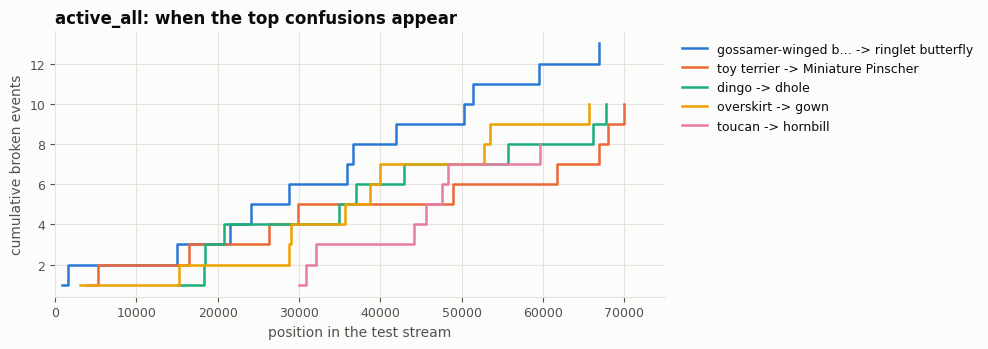

In [7]:
view.plot_onset();

The first two times Ramen makes its most frequent broken confusion. Top row: the query and the cache entries it retrieved with the largest weight (`w` = share of the update). Bottom rows: the most recent images in the queue of the class it predicted. Red = filed under a class that is not the image's true class.

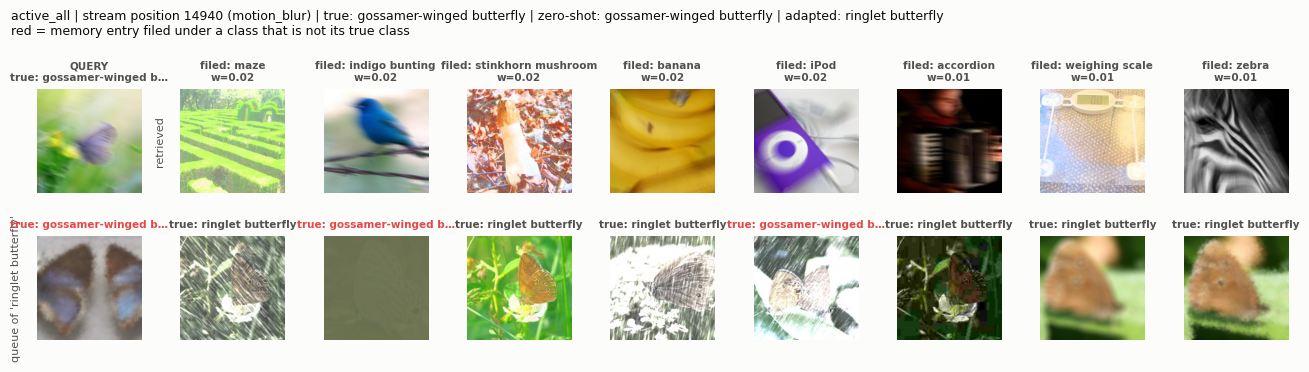

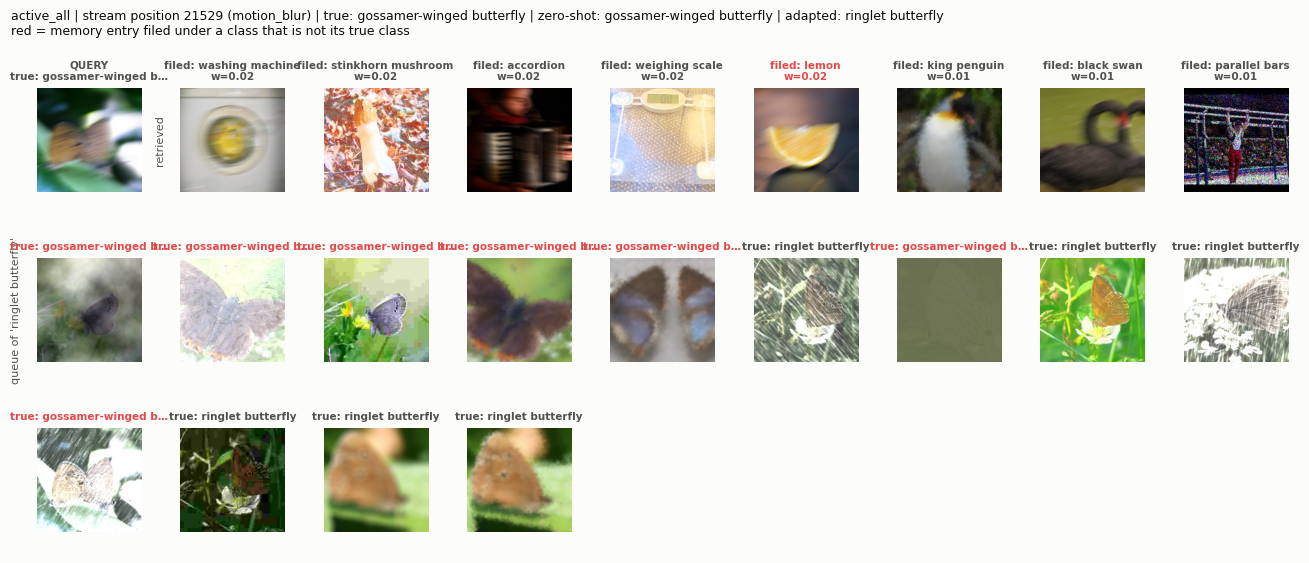

In [8]:
(true_name, pred_name) = view.pairs(top=1).index[0].split(' -> ')
view.show_pair(true_name, pred_name, n=2);

### The best zero-shot-weighted variant
The same view for the most accurate non-`all` variant, then how often it still makes Ramen's top confusions.

In [9]:
best = summary(VARIANTS).drop('active_all').accuracy.idxmax()
print('best variant:', best)
best_view = CacheViewer(exp, best)
best_view.pairs()

best variant: active_prob_T3


,count,first position,median position,queue: query class %,queue: correctly filed %
gossamer-winged butterfly -> ringlet butterfly,19,92,36622.0,39.7,45.1
tabby cat -> Egyptian Mau,9,14935,38222.0,14.3,31.0
grasshopper -> cricket insect,9,6383,22723.0,21.1,16.0
stopwatch -> digital watch,8,19943,50230.0,19.8,42.7
Brittany dog -> Welsh Springer Spaniel,7,4719,28523.0,21.2,41.8
overskirt -> gown,7,3072,35697.0,12.9,30.1
macaw -> lorikeet,6,7720,21176.0,11.2,24.7
toy terrier -> Miniature Pinscher,6,3771,23095.0,41.5,9.8
Bernese Mountain Dog -> Greater Swiss Mountain Dog,6,5785,37430.5,19.6,7.4
hartebeest -> impala (antelope),6,8338,47320.5,12.2,16.1


In [10]:
ramen_pairs = view.pairs(top=10)
best_counts = best_view.pairs(top=10**6)['count']
pd.DataFrame({'Ramen': ramen_pairs['count'], best: best_counts.reindex(ramen_pairs.index).fillna(0).astype(int)})

,Ramen,active_prob_T3
gossamer-winged butterfly -> ringlet butterfly,13,19
toy terrier -> Miniature Pinscher,10,6
dingo -> dhole,10,4
overskirt -> gown,10,7
toucan -> hornbill,8,5
stopwatch -> digital watch,7,8
American coot -> duck,6,3
Welsh Springer Spaniel -> Brittany dog,6,0
German Shepherd Dog -> Australian Kelpie,6,2
Bernese Mountain Dog -> Greater Swiss Mountain Dog,6,6


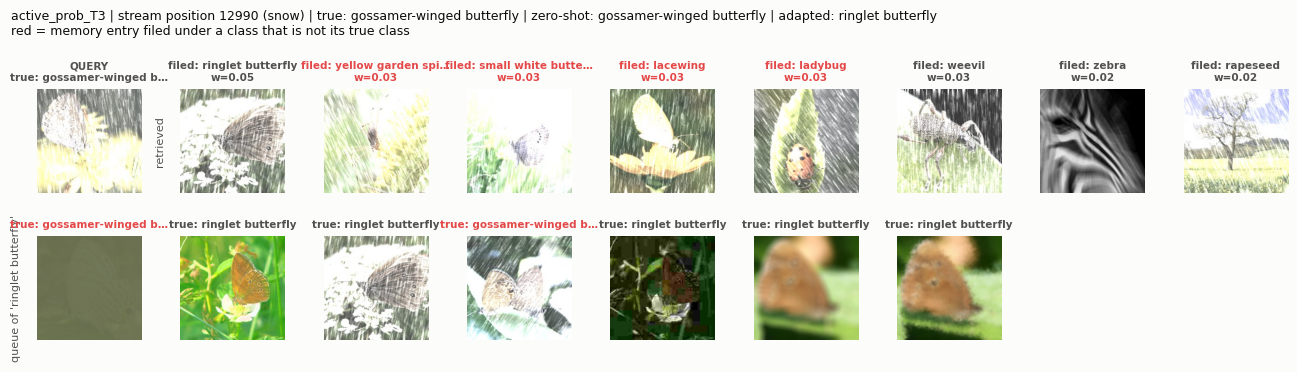

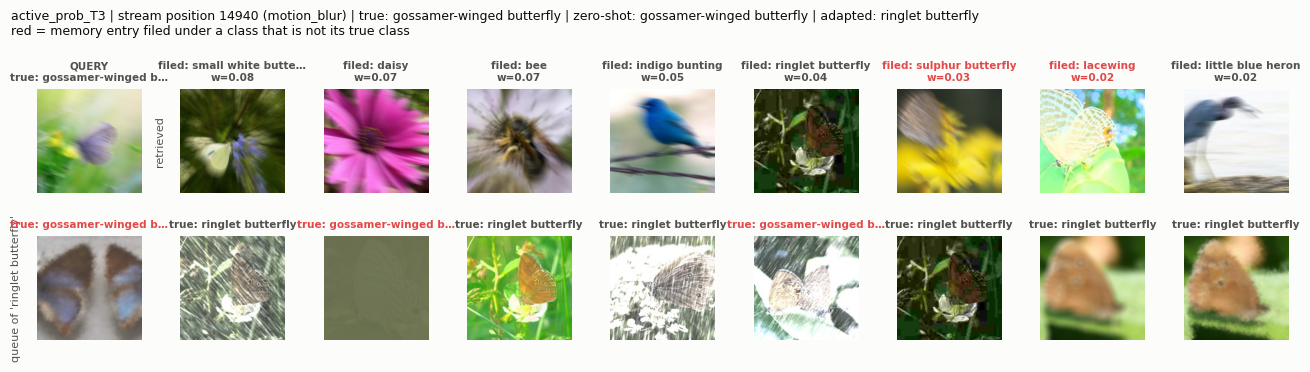

In [11]:
(true_name, pred_name) = best_view.pairs(top=1).index[0].split(' -> ')
best_view.show_pair(true_name, pred_name, n=2);

## Notes
- Seed 0 only. Before claiming a gain, run the winning variant at seeds 0-4 (`seed=` in `make_experiment`) and compare seed by seed with Ramen.
- Earlier results to keep in mind: restricting the support to cleaner entries (RamenClean, `agree` write rule) raised purity but lost accuracy because the effective support shrank, and per-sample adaptation alone was below Ramen on DomainNet. Small `top_m` shrinks the support the same way; check `self weight` alongside accuracy.
- `CacheViewer.show(position)` shows any single sample; `view.events()` gives the full per-event table to pick positions from (for example events late in the stream, when queues are full).